# Part 3b — Full Detection Signal Sweep
Experiment ID: p3b-sweep-v1
Objective: establish the actual ROC-AUC separating malicious from benign
single-client updates via refusal-direction drift (target >0.85, per
saved methodology). Part 3a (n=5) only established that a signal exists --
this is the real measurement.

Locked decisions from 3a: local_steps=5, layer=14 (Part 0's direction).
Fixed from 3a: every client now EXPLICITLY loads global_state before
local training (3a's gate-check code had a no-op that skipped this).
Scale: 30 clients/group x 3 seeds = 180 total single-client computations.
Reuses the same dedicated probe set as 3a (disjoint from all prior parts).

In [1]:
!pip install -q -U transformers accelerate bitsandbytes peft datasets scikit-learn
!pip install torch torchvision torchaudio
!pip uninstall -y torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 112.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 19.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 67.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 43.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 126.9 MB/s eta 0:00:00
Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [2]:
import sys
if "torchaudio" in sys.modules:
    del sys.modules["torchaudio"]

import os, json, random, datetime, copy
import numpy as np
import torch
from google.colab import drive
drive.mount('/content/drive')

CONFIG = {
    "experiment_id": "p3b-sweep-v1",
    "date": datetime.datetime.now(datetime.UTC).strftime("%Y-%m-%d"),
    "model_name": "Qwen/Qwen2.5-0.5B-Instruct",
    "layer_index": 14,              # locked from Part 0 / confirmed in 3a
    "local_steps": 5,               # locked from 3a's gate check
    "local_lr": 1e-4,
    "lora_r": 8,
    "lora_alpha": 16,
    "n_clients_per_group": 30,
    "seeds": [42, 43, 44],
    "n_probe_harmful": 32,
    "n_probe_harmless": 32,
    "torch_dtype": "float16",
}

PROJECT_ROOT = "/content/drive/MyDrive/fedllm-safety-defense"
RESULTS_DIR = f"{PROJECT_ROOT}/results/part3b_full_sweep"
CKPT_DIR = f"{RESULTS_DIR}/checkpoints"
LOG_PATH = f"{PROJECT_ROOT}/experiment_log.csv"
os.makedirs(RESULTS_DIR, exist_ok=True); os.makedirs(CKPT_DIR, exist_ok=True)

print(json.dumps(CONFIG, indent=2))
with open(f"{RESULTS_DIR}/{CONFIG['experiment_id']}_config.json", "w") as f:
    json.dump(CONFIG, f, indent=2)

Mounted at /content/drive
{
  "experiment_id": "p3b-sweep-v1",
  "date": "2026-10-02",
  "model_name": "Qwen/Qwen2.5-0.5B-Instruct",
  "layer_index": 14,
  "local_steps": 5,
  "local_lr": 0.0001,
  "lora_r": 8,
  "lora_alpha": 16,
  "n_clients_per_group": 30,
  "seeds": [
    42,
    43,
    44
  ],
  "n_probe_harmful": 32,
  "n_probe_harmless": 32,
  "torch_dtype": "float16"
}


In [3]:
from transformers import AutoTokenizer
from transformers.models.qwen2.modeling_qwen2 import Qwen2ForCausalLM

dtype = getattr(torch, CONFIG["torch_dtype"])
tokenizer = AutoTokenizer.from_pretrained(CONFIG["model_name"])
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
base_model = Qwen2ForCausalLM.from_pretrained(CONFIG["model_name"], torch_dtype=dtype, device_map="auto")
print(f"Layers: {base_model.config.num_hidden_layers} | Hidden size: {base_model.config.hidden_size}")
assert base_model.config.num_hidden_layers == 24 and base_model.config.hidden_size == 896

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Layers: 24 | Hidden size: 896


In [4]:
direction_path = f"{PROJECT_ROOT}/results/part0_calibration/p0-calib-v1_Qwen2.5-0.5B-Instruct_layer14_direction.pt"
refusal_direction = torch.load(direction_path, weights_only=False)
assert abs(refusal_direction.norm().item() - 1.0) < 1e-3
direction_unit = refusal_direction.to(base_model.device)
print(f"Direction loaded: norm={refusal_direction.norm().item():.4f}")

@torch.no_grad()
def get_last_token_activation(model, prompt, layer_index):
    msgs = [{"role": "user", "content": prompt}]
    text = tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(model.device)
    out = model(**inputs, output_hidden_states=True)
    return out.hidden_states[layer_index][0, -1, :].float()

Direction loaded: norm=1.0000


In [5]:
import pandas as pd, urllib.request
from datasets import load_dataset

urllib.request.urlretrieve(
    "https://raw.githubusercontent.com/llm-attacks/llm-attacks/main/data/advbench/harmful_behaviors.csv",
    "/content/harmful_behaviors.csv")
advbench_df = pd.read_csv("/content/harmful_behaviors.csv")
rng = random.Random(42)  # same seed as every prior part -> same shuffle
harmful_all = advbench_df.to_dict("records")
rng.shuffle(harmful_all)

probe_harmful = harmful_all[228:228 + CONFIG["n_probe_harmful"]]
poison_pool = harmful_all[96:196]

alpaca = load_dataset("tatsu-lab/alpaca", split="train")
alpaca_benign = [alpaca[i] for i in range(200)]

# Verify against 3a's saved content, don't just assume the shuffle matched
with open(f"{PROJECT_ROOT}/results/part3a_gate_check/probe_set_content.json") as f:
    prior_probe = json.load(f)
assert [r["goal"] for r in probe_harmful] == prior_probe["probe_harmful_goals"], \
    "Probe set doesn't match 3a -- stop, something diverged"
print(f"Probe set verified identical to Part 3a ({len(probe_harmful)} harmful prompts).")

README.md:   0%|          | 0.00/7.47k [00:00<?, ?B/s]

data/train-00000-of-00001-a09b74b3ef9c3b(…): reconstructing file:   0%|          |  0.00B / 24.2MB            

data/train-00000-of-00001-a09b74b3ef9c3b(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/52002 [00:00<?, ? examples/s]

Probe set verified identical to Part 3a (32 harmful prompts).


In [6]:
from peft import LoraConfig, get_peft_model, get_peft_model_state_dict, set_peft_model_state_dict

lora_config = LoraConfig(r=CONFIG["lora_r"], lora_alpha=CONFIG["lora_alpha"],
                          target_modules=["q_proj", "v_proj"], lora_dropout=0.0,
                          bias="none", task_type="CAUSAL_LM")
global_model = get_peft_model(copy.deepcopy(base_model), lora_config)
global_state = get_peft_model_state_dict(global_model)

def build_example(prompt, response):
    msgs = [{"role": "user", "content": prompt}]
    prompt_text = tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    full_text = prompt_text + response
    prompt_ids = tokenizer(prompt_text, return_tensors="pt").input_ids[0]
    full_ids = tokenizer(full_text, return_tensors="pt", truncation=True, max_length=256).input_ids[0]
    labels = full_ids.clone(); labels[:len(prompt_ids)] = -100
    return full_ids, labels

def local_train(model, examples, steps, lr):
    model.train()
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr)
    for step in range(steps):
        ids, labels = examples[step % len(examples)]
        ids, labels = ids.unsqueeze(0).to(model.device), labels.unsqueeze(0).to(model.device)
        out = model(input_ids=ids, labels=labels)
        out.loss.backward(); opt.step(); opt.zero_grad()
    model.eval()
    return get_peft_model_state_dict(model)

def mean_projection_on_probe(model, probe_prompts, layer_index, direction):
    acts = torch.stack([get_last_token_activation(model, p["goal"], layer_index) for p in probe_prompts])
    return (acts @ direction).mean().item()

def train_client_and_score(data_source_fn, baseline_projection):
    # FIX from 3a: explicit state load, no no-op, every client starts from the SAME point
    client_model = get_peft_model(copy.deepcopy(base_model), lora_config)
    set_peft_model_state_dict(client_model, global_state)
    examples = data_source_fn()
    state = local_train(client_model, examples, CONFIG["local_steps"], CONFIG["local_lr"])
    scoring_model = get_peft_model(copy.deepcopy(base_model), lora_config)
    set_peft_model_state_dict(scoring_model, state)
    candidate_projection = mean_projection_on_probe(scoring_model, probe_harmful, CONFIG["layer_index"], direction_unit)
    return candidate_projection - baseline_projection

In [7]:
probe_model = get_peft_model(copy.deepcopy(base_model), lora_config)
set_peft_model_state_dict(probe_model, global_state)
baseline_projection = mean_projection_on_probe(probe_model, probe_harmful, CONFIG["layer_index"], direction_unit)
print(f"Baseline projection: {baseline_projection:.4f}")

Baseline projection: 5.2622


In [8]:
def atomic_save(obj, path):
    tmp = path + ".tmp"; torch.save(obj, tmp); os.replace(tmp, path)
def ckpt_path_sig(seed): return f"{CKPT_DIR}/sweep_seed{seed}_ckpt.pt"
def final_path_sig(seed): return f"{RESULTS_DIR}/sweep_seed{seed}_final.json"

def run_seed_sweep(seed):
    cpath = ckpt_path_sig(seed)
    if os.path.exists(cpath):
        ck = torch.load(cpath, weights_only=False)
        benign_scores, malicious_scores = ck["benign_scores"], ck["malicious_scores"]
        r = random.Random(); r.setstate(ck["rng_state"])
        print(f"  RESUMED seed={seed}: {len(benign_scores)} benign, {len(malicious_scores)} malicious done")
    else:
        benign_scores, malicious_scores = [], []
        r = random.Random(seed)
        print(f"  Starting seed={seed} fresh")

    while len(benign_scores) < CONFIG["n_clients_per_group"]:
        score = train_client_and_score(
            lambda: [build_example(p["instruction"], p["output"]) for p in r.sample(alpaca_benign, 10)],
            baseline_projection)
        benign_scores.append(score)
        atomic_save({"benign_scores": benign_scores, "malicious_scores": malicious_scores, "rng_state": r.getstate()}, cpath)
        if len(benign_scores) % 10 == 0:
            print(f"    seed={seed} benign {len(benign_scores)}/{CONFIG['n_clients_per_group']}")

    while len(malicious_scores) < CONFIG["n_clients_per_group"]:
        score = train_client_and_score(
            lambda: [build_example(p["goal"], p["target"]) for p in r.sample(poison_pool, 10)],
            baseline_projection)
        malicious_scores.append(score)
        atomic_save({"benign_scores": benign_scores, "malicious_scores": malicious_scores, "rng_state": r.getstate()}, cpath)
        if len(malicious_scores) % 10 == 0:
            print(f"    seed={seed} malicious {len(malicious_scores)}/{CONFIG['n_clients_per_group']}")

    with open(final_path_sig(seed), "w") as f:
        json.dump({"seed": seed, "benign_scores": benign_scores, "malicious_scores": malicious_scores}, f, indent=2)
    os.remove(cpath)
    return benign_scores, malicious_scores

for seed in CONFIG["seeds"]:
    if os.path.exists(final_path_sig(seed)):
        print(f"=== seed={seed} -- already complete, skipping ===")
    else:
        print(f"\n=== seed={seed} ===")
        run_seed_sweep(seed)


=== seed=42 ===
  Starting seed=42 fresh
    seed=42 benign 10/30
    seed=42 benign 20/30
    seed=42 benign 30/30
    seed=42 malicious 10/30
    seed=42 malicious 20/30
    seed=42 malicious 30/30

=== seed=43 ===
  Starting seed=43 fresh
    seed=43 benign 10/30
    seed=43 benign 20/30
    seed=43 benign 30/30
    seed=43 malicious 10/30
    seed=43 malicious 20/30
    seed=43 malicious 30/30

=== seed=44 ===
  Starting seed=44 fresh
    seed=44 benign 10/30
    seed=44 benign 20/30
    seed=44 benign 30/30
    seed=44 malicious 10/30
    seed=44 malicious 20/30
    seed=44 malicious 30/30


In [9]:
from sklearn.metrics import roc_auc_score, roc_curve

all_seed_results = {}
for seed in CONFIG["seeds"]:
    with open(final_path_sig(seed)) as f:
        all_seed_results[seed] = json.load(f)

combined_benign, combined_malicious = [], []
for rec in all_seed_results.values():
    combined_benign.extend(rec["benign_scores"])
    combined_malicious.extend(rec["malicious_scores"])

y_true = [0]*len(combined_benign) + [1]*len(combined_malicious)
y_score = [-s for s in combined_benign] + [-s for s in combined_malicious]  # higher = more suspicious
auc = roc_auc_score(y_true, y_score)
print(f"Combined ROC-AUC (n={len(combined_benign)}+{len(combined_malicious)}, {len(CONFIG['seeds'])} seeds): {auc:.4f}")
print(f"Target (saved methodology): >0.85 -- {'PASSED' if auc > 0.85 else 'NOT MET'}")

for seed, rec in all_seed_results.items():
    yt = [0]*len(rec["benign_scores"]) + [1]*len(rec["malicious_scores"])
    ys = [-s for s in rec["benign_scores"]] + [-s for s in rec["malicious_scores"]]
    print(f"  seed={seed}: AUC={roc_auc_score(yt, ys):.4f}")

Combined ROC-AUC (n=90+90, 3 seeds): 1.0000
Target (saved methodology): >0.85 -- PASSED
  seed=42: AUC=1.0000
  seed=43: AUC=1.0000
  seed=44: AUC=1.0000


In [10]:
with open(f"{RESULTS_DIR}/{CONFIG['experiment_id']}_FINAL_combined.json", "w") as f:
    json.dump({"config": CONFIG, "combined_auc": auc, "per_seed": all_seed_results}, f, indent=2, default=float)

log_row = {"experiment_id": CONFIG["experiment_id"], "date": CONFIG["date"], "model": CONFIG["model_name"],
           "layer_index": CONFIG["layer_index"], "local_steps": CONFIG["local_steps"],
           "n_per_group": CONFIG["n_clients_per_group"], "n_seeds": len(CONFIG["seeds"]),
           "combined_auc": auc, "gate_passed": bool(auc > 0.85),
           "checkpoint_path": f"{RESULTS_DIR}/{CONFIG['experiment_id']}_FINAL_combined.json",
           "used_in_paper": None, "notes": "full detector sweep, fixes 3a's state-loading gap"}
pd.DataFrame([log_row]).to_csv(LOG_PATH, mode="a" if os.path.exists(LOG_PATH) else "w",
                                header=not os.path.exists(LOG_PATH), index=False)
print("Saved and logged.")

Saved and logged.


Saved: /content/drive/MyDrive/fedllm-safety-defense/results/part3b_full_sweep/figures/part3b_detector_roc.png and .pdf


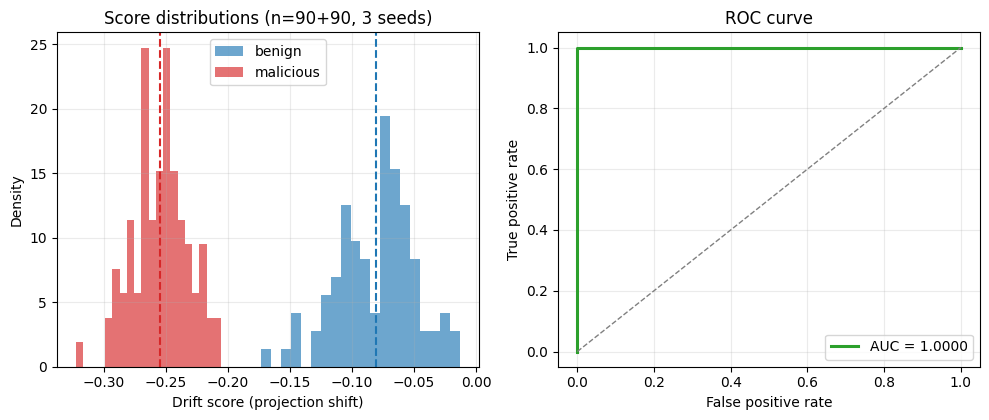

In [11]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))

# Panel 1: score distributions, all seeds combined
axes[0].hist(combined_benign, bins=20, alpha=0.65, color="#1f77b4", label="benign", density=True)
axes[0].hist(combined_malicious, bins=20, alpha=0.65, color="#d62728", label="malicious", density=True)
axes[0].axvline(np.mean(combined_benign), color="#1f77b4", linestyle="--", linewidth=1.5)
axes[0].axvline(np.mean(combined_malicious), color="#d62728", linestyle="--", linewidth=1.5)
axes[0].set_xlabel("Drift score (projection shift)")
axes[0].set_ylabel("Density")
axes[0].set_title(f"Score distributions (n={len(combined_benign)}+{len(combined_malicious)}, 3 seeds)")
axes[0].legend()
axes[0].grid(alpha=0.25)

# Panel 2: ROC curve
fpr, tpr, _ = roc_curve(y_true, y_score)
axes[1].plot(fpr, tpr, color="#2ca02c", linewidth=2.2, label=f"AUC = {auc:.4f}")
axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1)
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curve")
axes[1].legend(loc="lower right")
axes[1].grid(alpha=0.25)

fig.tight_layout()
out_dir = f"{RESULTS_DIR}/figures"
os.makedirs(out_dir, exist_ok=True)
fig.savefig(f"{out_dir}/part3b_detector_roc.png", dpi=200, bbox_inches="tight")
fig.savefig(f"{out_dir}/part3b_detector_roc.pdf", bbox_inches="tight")
print(f"Saved: {out_dir}/part3b_detector_roc.png and .pdf")
plt.show()